# 02 — Data Quality and Temporal Split

## 1. Objective

Assess the quality, consistency, and temporal integrity of the SWaT dataset before exploratory analysis and anomaly-detection modelling.

The assessment covers data provenance, schema consistency, missing and invalid values, duplicate records, timestamp ordering, label integrity, and reconciliation between the separate and merged CSV files.

The findings will guide data preparation and the design of chronological evaluation partitions. Any data-quality issue that could affect model development or evaluation will be documented before proceeding.

## 2. Scope

This notebook will:

- Establish the dataset files and their structural characteristics.
- Verify column names, schema consistency, and data types.
- Assess missing values, invalid values, and duplicate records.
- Investigate timestamp ordering and temporal continuity.
- Examine the distribution and consistency of anomaly labels.
- Reconcile `normal.csv`, `attack.csv`, and `merged.csv`.
- Define an appropriate chronological partitioning strategy.
- Document data-quality limitations and their implications for subsequent analysis.

## 3. Data Handling Principles

- Preserve the original files in `data/raw/` without modification.
- Use the existing project paths rather than hardcoded machine-specific paths.
- Process large CSV files in chunks when a complete in-memory load is unnecessary.
- Distinguish verified findings from unresolved questions.
- Preserve temporal order when designing evaluation partitions.
- Document any preprocessing decisions that could affect anomaly detection or evaluation.

## 4. Expected Outcome

By the end of this notebook, the dataset's principal quality issues and temporal characteristics should be documented, file consistency should be assessed, and the rationale for the evaluation partitions should be established.

The notebook will provide the data-quality evidence needed before proceeding to **Notebook 03 — Exploratory Analysis**.

In [3]:
# Universal Path and Environment Setup (Kaggle / Local / Colab)
import os, sys
from pathlib import Path

# Bulletproof environment detection
IS_KAGGLE = (os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None) or (os.name != 'nt' and Path('/kaggle/input').is_dir())
IS_COLAB = ('google.colab' in sys.modules) or (os.name != 'nt' and Path('/content').is_dir() and not IS_KAGGLE)

raw_dir = None
if IS_KAGGLE:
    for p in Path('/kaggle/input').rglob('normal.csv'):
        if p.is_file(): raw_dir = p.parent; break
elif IS_COLAB:
    for p in Path('/content').rglob('normal.csv'):
        if p.is_file(): raw_dir = p.parent; break
else:
    cwd = Path.cwd().resolve()
    for cand in [cwd / 'data' / 'raw', cwd.parent / 'data' / 'raw', cwd / 'swat-dataset']:
        if (cand / 'normal.csv').is_file(): raw_dir = cand; break

if raw_dir is None:
    raise FileNotFoundError('Could not locate raw data directory containing normal.csv and attack.csv.')

FILES = {
    'normal': raw_dir / 'normal.csv',
    'attack': raw_dir / 'attack.csv',
    'merged': raw_dir / 'merged.csv',
}
print(f"[ENV] Environment: {'Kaggle' if IS_KAGGLE else ('Colab' if IS_COLAB else 'Local')}")
for name, p in FILES.items():
    print(f"  {name:6s}: {p.name} ({p.stat().st_size:,} bytes, exists: {p.is_file()})")


[ENV] Environment: Kaggle
  normal: normal.csv (402,374,633 bytes, exists: True)
  attack: attack.csv (15,162,438 bytes, exists: True)
  merged: merged.csv (426,855,390 bytes, exists: True)


## 5. Dataset Inventory

The raw dataset directory contains three CSV files: `normal.csv`, `attack.csv`, and `merged.csv`.

| File | Size (bytes) | Intended role |
|---|---:|---|
| `normal.csv` | 402,374,633 | Records designated as normal operation |
| `attack.csv` | 15,162,438 | Records associated with attack scenarios |
| `merged.csv` | 426,855,390 | Combined dataset containing normal and attack records |

The files are stored in `data/raw/`. Their existence and file sizes have been verified programmatically.

These checks establish the initial file inventory only. They do not establish that the files contain valid records, that `merged.csv` is an exact combination of the other two files, or that their timestamps are correctly ordered. Those properties require separate validation.

In [4]:
import csv

schemas = {}

for name, path in FILES.items():
    with path.open("r", encoding="utf-8-sig", newline="") as file:
        reader = csv.reader(file)
        headers = next(reader)

    normalized_headers = [header.strip() for header in headers]

    schemas[name] = normalized_headers

    print(f"{name}: {len(headers)} columns")

    if len(normalized_headers) != len(set(normalized_headers)):
        raise ValueError(f"{name} contains duplicate column names after trimming whitespace.")

reference_schema = schemas["normal"]

for name, schema in schemas.items():
    if schema != reference_schema:
        raise ValueError(f"{name} has a different column order or schema from normal.csv.")

print("\nPASS: All three files have matching column names and column order.")
print("PASS: No duplicate column names were found after trimming whitespace.")

normal: 53 columns
attack: 53 columns
merged: 53 columns

PASS: All three files have matching column names and column order.
PASS: No duplicate column names were found after trimming whitespace.


## 6. Schema Consistency

All three raw CSV files contain **53 columns**. After removing leading and trailing whitespace from the column names, the files have identical column names and column order.

No duplicate column names were identified after normalization.

The raw headers contain leading whitespace, so column names should be normalized during analysis rather than modifying the original CSV files. The raw files remain preserved unchanged.

Schema consistency is therefore **PASS** across `normal.csv`, `attack.csv`, and `merged.csv`.

In [5]:
import pandas as pd
import numpy as np

CHUNK_SIZE = 100_000

missing_results = {}

for name, path in FILES.items():
    missing_counts = pd.Series(dtype="int64")
    row_count = 0

    for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE):
        chunk.columns = chunk.columns.str.strip()
        row_count += len(chunk)

        chunk_missing = chunk.isna().sum()

        if missing_counts.empty:
            missing_counts = chunk_missing.astype("int64")
        else:
            missing_counts = missing_counts.add(chunk_missing, fill_value=0).astype("int64")

    missing_results[name] = {
        "rows": row_count,
        "missing_total": int(missing_counts.sum()),
        "columns_with_missing": missing_counts[missing_counts > 0].sort_values(ascending=False),
    }

    print(f"{name}:")
    print(f"  rows: {row_count:,}")
    print(f"  total missing values: {int(missing_counts.sum()):,}")
    print(f"  columns with missing values: {len(missing_counts[missing_counts > 0])}")

    if (missing_counts > 0).any():
        print(missing_counts[missing_counts > 0])
    else:
        print("  No missing values found.")

    print()

normal:
  rows: 1,387,098
  total missing values: 6,942,600
  columns with missing values: 7
MV101     991800
AIT201    991800
MV201     991800
P201      991800
P202      991800
P204      991800
MV303     991800
dtype: int64

attack:
  rows: 54,621
  total missing values: 0
  columns with missing values: 0
  No missing values found.

merged:
  rows: 1,441,719
  total missing values: 6,942,600
  columns with missing values: 7
MV101     991800
AIT201    991800
MV201     991800
P201      991800
P202      991800
P204      991800
MV303     991800
dtype: int64



## 7. Missing Value Assessment

The missing-value assessment identified missing observations in seven variables:

- `MV101`
- `AIT201`
- `MV201`
- `P201`
- `P202`
- `P204`
- `MV303`

Each affected variable contains **991,800 missing values** in `normal.csv`, giving **6,942,600 missing cells** across the seven variables.

`attack.csv` contains **no missing values**. The same 6,942,600 missing cells are present in `merged.csv`, which is consistent with the missing values originating from the normal-operation records.

These missing values are not removed or imputed at this stage. Their temporal and process context must be investigated before determining whether they represent genuine sensor/actuator availability, structural missingness, or a data-quality problem.

**Status: Investigation required.**

In [6]:
MISSING_COLUMNS = [
    "MV101", "AIT201", "MV201", "P201",
    "P202", "P204", "MV303",
]

with FILES["normal"].open("r", encoding="utf-8-sig", newline="") as file:
    raw_headers = next(csv.reader(file))

selected_columns = [
    header for header in raw_headers
    if header.strip() == "Timestamp"
    or header.strip() in MISSING_COLUMNS
]

if len(selected_columns) != len(MISSING_COLUMNS) + 1:
    raise ValueError(
        f"Expected {len(MISSING_COLUMNS) + 1} columns, "
        f"but found {len(selected_columns)}."
    )

missing_time_results = []
total_rows_with_missing_values = 0
total_invalid_timestamps = 0

for chunk in pd.read_csv(
    FILES["normal"],
    usecols=selected_columns,
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()

    chunk["Timestamp"] = pd.to_datetime(
        chunk["Timestamp"].str.strip(),
        format="%d/%m/%Y %I:%M:%S %p",
        errors="coerce",
    )

    total_invalid_timestamps += int(chunk["Timestamp"].isna().sum())

    missing_mask = chunk[MISSING_COLUMNS].isna().any(axis=1)
    affected = chunk.loc[missing_mask, "Timestamp"]

    total_rows_with_missing_values += int(missing_mask.sum())

    if missing_mask.any():
        missing_time_results.append({
            "first_timestamp": affected.min(),
            "last_timestamp": affected.max(),
            "affected_rows": int(missing_mask.sum()),
        })

print(f"Total rows with missing values: {total_rows_with_missing_values:,}")
print(f"Total invalid timestamps: {total_invalid_timestamps:,}")
print(f"Chunks containing missing values: {len(missing_time_results)}")

if missing_time_results:
    print(
        "Overall first timestamp:",
        min(r["first_timestamp"] for r in missing_time_results),
    )
    print(
        "Overall last timestamp:",
        max(r["last_timestamp"] for r in missing_time_results),
    )

if total_rows_with_missing_values != 991_800:
    raise ValueError(
        "The observed number of rows with missing values does not match "
        "the previously recorded count of 991,800."
    )

if total_invalid_timestamps:
    raise ValueError(
        f"Found {total_invalid_timestamps:,} invalid timestamps; "
        "investigate before interpreting the time range."
    )

Total rows with missing values: 991,800
Total invalid timestamps: 0
Chunks containing missing values: 11
Overall first timestamp: 2015-12-22 16:00:00
Overall last timestamp: 2015-12-28 09:59:59


## 8. Temporal Assessment of Missing Values

The temporal investigation examined the seven variables previously identified as containing missing values in `normal.csv`.

The check identified 991,800 rows containing at least one missing value in these variables. This matches the count established during the initial missing-value assessment. No invalid timestamps were detected.

The affected rows span the following observed timestamp range:

- **First affected timestamp:** 22 December 2015, 16:00:00
- **Last affected timestamp:** 28 December 2015, 09:59:59

The affected rows were found in 11 processing chunks. These findings establish the overall time range of the missingness but do not, by themselves, establish that every affected row belongs to one continuous block.

The last affected timestamp is 2015-12-28 09:59:59, one second before 2015-12-28 10:00:00 — which the merged-file boundary check (Section 13) confirms as the first row of merged.csv, and therefore of normal.csv. This is consistent with the missing block occupying the beginning of the file but requires direct confirmation.

No missing values have been imputed, and no rows have been removed. The cause and operational significance of the missingness remain unresolved and must be considered before selecting a treatment strategy.

**Status: Temporal range established; cause not yet determined.**

## 9. Timestamp Ordering Assessment

A chunked scan of `normal.csv` confirmed two backward timestamp transitions and established the exact extent of the missing-value block.

| Previous data row | Next data row | Previous timestamp | Next timestamp |
|---:|---:|---|---|
| 395,298 | 395,299 | `2016-01-02 14:59:59` | `2015-12-22 16:00:00` |
| 892,098 | 892,099 | `2015-12-28 09:59:59` | `2015-12-22 16:30:00` |

Data-row numbers are 1-indexed and exclude the header.

### Relationship to the Missing-Value Pattern

The scan identified one continuous block of **991,800 rows** containing missing values across the seven previously identified variables. The block begins at data row 395,299 and extends to the end of `normal.csv`, at data row 1,387,098.

The block's first and last timestamps are `2015-12-22 16:00:00` and `2015-12-28 09:59:59`, respectively. Both backward timestamp transitions occur within this block's boundaries: the first marks its beginning, while the second marks a restart at `2015-12-22 16:30:00`.

These findings confirm a positional relationship between the missing values and the timestamp discontinuities. They do not, by themselves, establish the cause of the missingness or explain the overlapping timestamp sequences.

### Implications for Data Preparation

The original row order must be preserved while the file structure is investigated. Sorting solely by timestamp or removing repeated timestamps could alter the relationship between observations and their original positions.

The next validation step is to examine `merged.csv` and reconcile its row structure with `normal.csv` and `attack.csv`. No rows will be removed, reordered, or imputed until the structure and implications of these findings have been established.

**Status: Missing-value block and timestamp discontinuities verified in `normal.csv`; cause and cross-file reconciliation remain under investigation.**

In [7]:
with FILES["normal"].open("r", encoding="utf-8-sig", newline="") as file:
    raw_headers = next(csv.reader(file))

selected_columns = [
    header for header in raw_headers
    if header.strip() == "Timestamp"
    or header.strip() in MISSING_COLUMNS
]

if len(selected_columns) != 8:
    raise ValueError(f"Expected 8 columns; found {len(selected_columns)}.")

missing_runs = []
backward_transitions = []
total_missing_rows = 0
total_invalid_timestamps = 0
total_rows = 0
previous_timestamp = None
previous_missing = False

for chunk in pd.read_csv(
    FILES["normal"],
    usecols=selected_columns,
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()

    timestamps = pd.to_datetime(
        chunk["Timestamp"].str.strip(),
        format="%d/%m/%Y %I:%M:%S %p",
        errors="coerce",
    )

    total_invalid_timestamps += int(timestamps.isna().sum())

    missing_mask = chunk[MISSING_COLUMNS].isna().any(axis=1).to_numpy()
    total_missing_rows += int(missing_mask.sum())

    row_start = total_rows + 1

    if previous_timestamp is not None and len(timestamps):
        if timestamps.iloc[0] < previous_timestamp:
            backward_transitions.append({
                "previous_data_row": row_start - 1,
                "next_data_row": row_start,
                "previous_timestamp": previous_timestamp,
                "next_timestamp": timestamps.iloc[0],
            })

    backward_positions = np.flatnonzero(
        timestamps.diff().lt(pd.Timedelta(0)).to_numpy()
    )

    for position in backward_positions:
        backward_transitions.append({
            "previous_data_row": row_start + int(position) - 1,
            "next_data_row": row_start + int(position),
            "previous_timestamp": timestamps.iloc[position - 1],
            "next_timestamp": timestamps.iloc[position],
        })

    boundaries = np.flatnonzero(
        np.diff(np.r_[False, missing_mask, False].astype(np.int8))
    )

    for start, end in boundaries.reshape(-1, 2):
        run_end = row_start + int(end) - 1

        if start == 0 and previous_missing:
            missing_runs[-1]["last_data_row"] = run_end
            missing_runs[-1]["last_timestamp"] = timestamps.iloc[end - 1]
            missing_runs[-1]["rows"] += int(end - start)
        else:
            missing_runs.append({
                "first_data_row": row_start + int(start),
                "last_data_row": run_end,
                "first_timestamp": timestamps.iloc[start],
                "last_timestamp": timestamps.iloc[end - 1],
                "rows": int(end - start),
            })

    if len(missing_mask):
        previous_missing = bool(missing_mask[-1])

    if len(timestamps):
        previous_timestamp = timestamps.iloc[-1]

    total_rows += len(chunk)

print(f"Total data rows: {total_rows:,}")
print(f"Rows containing missing values: {total_missing_rows:,}")
print(f"Invalid timestamps: {total_invalid_timestamps:,}")

if total_missing_rows != 991_800:
    raise ValueError(
        "Missing-row count does not match the previously verified count of 991,800."
    )

if total_invalid_timestamps:
    raise ValueError(
        f"Found {total_invalid_timestamps:,} invalid timestamps across the file."
    )

print("\nContiguous runs of rows containing missing values:")
for run in missing_runs:
    print(run)

print("\nBackward timestamp transitions (1-indexed data rows, excluding header):")
for transition in backward_transitions:
    print(transition)

Total data rows: 1,387,098
Rows containing missing values: 991,800
Invalid timestamps: 0

Contiguous runs of rows containing missing values:
{'first_data_row': 395299, 'last_data_row': 1387098, 'first_timestamp': Timestamp('2015-12-22 16:00:00'), 'last_timestamp': Timestamp('2015-12-28 09:59:59'), 'rows': 991800}

Backward timestamp transitions (1-indexed data rows, excluding header):
{'previous_data_row': 395298, 'next_data_row': 395299, 'previous_timestamp': Timestamp('2016-01-02 14:59:59'), 'next_timestamp': Timestamp('2015-12-22 16:00:00')}
{'previous_data_row': 892098, 'next_data_row': 892099, 'previous_timestamp': Timestamp('2015-12-28 09:59:59'), 'next_timestamp': Timestamp('2015-12-22 16:30:00')}


In [8]:
SEGMENT_A_START = 395_299
SEGMENT_A_END = 892_098
SEGMENT_B_START = 892_099
SEGMENT_B_END = 1_387_098

with FILES["normal"].open("r", encoding="utf-8-sig", newline="") as file:
    raw_headers = next(csv.reader(file))

columns_to_read = [
    header
    for header in raw_headers
    if header.strip() == "Timestamp"
    or header.strip() not in MISSING_COLUMNS
]

segment_a_parts = []
segment_b_parts = []
row_offset = 0

for chunk in pd.read_csv(
    FILES["normal"],
    usecols=columns_to_read,
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()

    chunk_start = row_offset + 1
    chunk_end = row_offset + len(chunk)

    for start, end, parts in (
        (SEGMENT_A_START, SEGMENT_A_END, segment_a_parts),
        (SEGMENT_B_START, SEGMENT_B_END, segment_b_parts),
    ):
        overlap_start = max(start, chunk_start)
        overlap_end = min(end, chunk_end)

        if overlap_start <= overlap_end:
            parts.append(
                chunk.iloc[
                    overlap_start - chunk_start:
                    overlap_end - chunk_start + 1
                ].copy()
            )

    row_offset += len(chunk)

if row_offset != 1_387_098:
    raise ValueError(f"Expected 1,387,098 data rows; found {row_offset:,}.")

segment_a_df = pd.concat(segment_a_parts, ignore_index=True)
segment_b_df = pd.concat(segment_b_parts, ignore_index=True)

if len(segment_a_df) != 496_800 or len(segment_b_df) != 495_000:
    raise ValueError("Extracted segment lengths do not match the verified boundaries.")

OFFSET = len(segment_a_df) - len(segment_b_df)

if OFFSET != 1_800:
    raise ValueError(f"Expected an offset of 1,800 rows; found {OFFSET:,}.")

aligned_a = segment_a_df.iloc[OFFSET:].reset_index(drop=True)
aligned_b = segment_b_df.reset_index(drop=True)

timestamps_a = pd.to_datetime(
    aligned_a["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

timestamps_b = pd.to_datetime(
    aligned_b["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

timestamp_matches = timestamps_a.eq(timestamps_b)

feature_columns = [
    column
    for column in aligned_a.columns
    if column != "Timestamp"
]

values_a = aligned_a[feature_columns]
values_b = aligned_b[feature_columns]

feature_matches = (
    values_a.eq(values_b) | (values_a.isna() & values_b.isna())
).all(axis=1)

full_matches = timestamp_matches & feature_matches

print(f"Segment A rows: {len(segment_a_df):,}")
print(f"Segment B rows: {len(segment_b_df):,}")
print(f"Offset: {OFFSET:,} rows")
print(f"Aligned rows: {len(aligned_a):,}")
print(f"Segment A aligned start: {timestamps_a.iloc[0]}")
print(f"Segment B aligned start: {timestamps_b.iloc[0]}")
print(f"Segment A aligned end: {timestamps_a.iloc[-1]}")
print(f"Segment B aligned end: {timestamps_b.iloc[-1]}")
print(f"Matching timestamps: {int(timestamp_matches.sum()):,}")
print(f"Matching feature rows: {int(feature_matches.sum()):,}")
print(f"Matching timestamps and features: {int(full_matches.sum()):,}")
print(f"Timestamp mismatches: {int((~timestamp_matches).sum()):,}")
print(f"Feature mismatches: {int((~feature_matches).sum()):,}")

if not full_matches.all():
    mismatch_positions = np.flatnonzero(~full_matches.to_numpy())

    print("\nFirst 10 mismatches:")

    for position in mismatch_positions[:10]:
        print({
            "aligned_position": int(position),
            "segment_a_data_row": SEGMENT_A_START + OFFSET + int(position),
            "segment_b_data_row": SEGMENT_B_START + int(position),
            "timestamp_a": timestamps_a.iloc[position],
            "timestamp_b": timestamps_b.iloc[position],
            "timestamp_match": bool(timestamp_matches.iloc[position]),
            "feature_match": bool(feature_matches.iloc[position]),
        })

Segment A rows: 496,800
Segment B rows: 495,000
Offset: 1,800 rows
Aligned rows: 495,000
Segment A aligned start: 2015-12-22 16:30:00
Segment B aligned start: 2015-12-22 16:30:00
Segment A aligned end: 2015-12-28 09:59:59
Segment B aligned end: 2015-12-28 09:59:59
Matching timestamps: 495,000
Matching feature rows: 495,000
Matching timestamps and features: 495,000
Timestamp mismatches: 0
Feature mismatches: 0


## 10. Duplicate Segment Investigation

A row-by-row comparison was conducted between the two segments of `normal.csv` containing missing values in seven variables.

The first segment contains 496,800 rows, beginning at `2015-12-22 16:00:00`. The second contains 495,000 rows, beginning at `2015-12-22 16:30:00`. Both end at `2015-12-28 09:59:59`.

After aligning the first segment by the 1,800-row difference, all 495,000 corresponding rows matched exactly across timestamps, the 44 non-missing sensor features, and the `Normal/Attack` label column (45 non-Timestamp columns in total). No timestamp or feature mismatches were found.

This establishes that the two segments are exact duplicates over their shared time interval. The additional 1,800 rows in the first segment cover the initial 30 minutes.

**Important correction:** A later cell labelled “Verify the known duplicate segment” returns `Exact duplicate segment: False`. That check is misaligned: it compares `normal_part_a.iloc[:495000]` with `normal_part_a.iloc[1800:]` from the same 496,800-row extract, rather than comparing Segment A with Segment B. Its `False` result is therefore not a valid contradiction of the Segment A vs Segment B comparison above and should not be used.

In [9]:
attack = pd.read_csv(
    FILES["attack"],
    encoding="utf-8-sig",
)

attack.columns = attack.columns.str.strip()

if "Timestamp" not in attack.columns:
    raise ValueError("Timestamp column not found in attack.csv.")

attack["Timestamp"] = pd.to_datetime(
    attack["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

duplicate_timestamps = attack["Timestamp"].duplicated(keep=False)
duplicate_rows = attack.duplicated(keep=False)

print(f"Total rows: {len(attack):,}")
print(f"Unique timestamps: {attack['Timestamp'].nunique():,}")
print(f"Rows with repeated timestamps: {int(duplicate_timestamps.sum()):,}")
print(
    "Distinct repeated timestamp values: "
    f"{attack.loc[duplicate_timestamps, 'Timestamp'].nunique():,}"
)
print(f"Rows participating in exact duplicate records: {int(duplicate_rows.sum()):,}")
print(f"Exact duplicate records beyond first occurrences: {int(attack.duplicated().sum()):,}")

chronologically_ordered = attack["Timestamp"].is_monotonic_increasing
print(f"Chronologically ordered: {chronologically_ordered}")

if not chronologically_ordered:
    backward_positions = np.flatnonzero(
        attack["Timestamp"].diff().lt(pd.Timedelta(0)).to_numpy()
    )

    print("\nFirst 20 backward timestamp transitions:")

    for position in backward_positions[:20]:
        print({
            "previous_data_row": int(position),
            "next_data_row": int(position) + 1,
            "previous_timestamp": attack["Timestamp"].iloc[position - 1],
            "next_timestamp": attack["Timestamp"].iloc[position],
        })


Total rows: 54,621
Unique timestamps: 54,621
Rows with repeated timestamps: 0
Distinct repeated timestamp values: 0
Rows participating in exact duplicate records: 0
Exact duplicate records beyond first occurrences: 0
Chronologically ordered: True


## 11. Attack Dataset Quality Assessment

The assessment of `attack.csv` identified 54,621 records and 54,621 unique timestamps.

No repeated timestamps or exact duplicate records were found. The timestamp sequence is monotonically increasing, confirming that the file is chronologically ordered.

These results distinguish `attack.csv` from `normal.csv`, where a continuous block of missing values and duplicated observations was identified.

**Status: PASS for timestamp uniqueness, exact-record duplication, and chronological ordering.**

In [10]:
merged = pd.read_csv(
    FILES["merged"],
    encoding="utf-8-sig",
)

merged.columns = merged.columns.str.strip()

if "Timestamp" not in merged.columns:
    raise ValueError("Timestamp column not found in merged.csv.")

merged["Timestamp"] = pd.to_datetime(
    merged["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

duplicate_timestamps = merged["Timestamp"].duplicated(keep=False)
duplicate_rows = merged.duplicated(keep=False)

print(f"Total rows: {len(merged):,}")
print(f"Expected rows from source files: {len(attack) + missing_results['normal']['rows']:,}")
print(f"Unique timestamps: {merged['Timestamp'].nunique():,}")
print(f"Rows with repeated timestamps: {int(duplicate_timestamps.sum()):,}")
print(f"Distinct repeated timestamp values: {merged.loc[duplicate_timestamps, 'Timestamp'].nunique():,}")
print(f"Rows participating in exact duplicate records: {int(duplicate_rows.sum()):,}")
print(f"Exact duplicate records beyond first occurrences: {int(merged.duplicated().sum()):,}")
print(f"Chronologically ordered: {merged['Timestamp'].is_monotonic_increasing}")

Total rows: 1,441,719
Expected rows from source files: 1,441,719
Unique timestamps: 946,719
Rows with repeated timestamps: 990,000
Distinct repeated timestamp values: 495,000
Rows participating in exact duplicate records: 990,000
Exact duplicate records beyond first occurrences: 495,000
Chronologically ordered: False


## 12. Duplicate Records and Timestamp Integrity

### Attack Dataset

The `attack.csv` dataset contains 54,621 records, each with a unique timestamp. No repeated timestamps or exact duplicate records were identified. The records are chronologically ordered.

### Merged Dataset

The `merged.csv` dataset contains 1,441,719 records, matching the combined row count of `normal.csv` and `attack.csv`.

The assessment identified 495,000 distinct timestamp values that occur more than once. In total, 990,000 rows participate in repeated timestamp groups, with 495,000 duplicate records beyond the first occurrences. The dataset is not chronologically ordered.

These findings are consistent with the previously verified duplicated segment in `normal.csv`. The repeated observations and backward timestamp transitions must be considered when establishing chronological evaluation partitions.

### Data Handling Decision

The original CSV files remain unchanged. No records have been removed, reordered, or imputed as part of this assessment.

The duplicate observations will not be removed automatically. Their treatment must be determined before the final modelling dataset and temporal evaluation partitions are established.

**Status:** Duplicate-record assessment completed. The implications for preprocessing and temporal evaluation remain to be addressed.

In [11]:
def read_timestamps(path):
    with path.open("r", encoding="utf-8-sig", newline="") as file:
        headers = next(csv.reader(file))

    timestamp_column = next(
        (header for header in headers if header.strip() == "Timestamp"),
        None,
    )

    if timestamp_column is None:
        raise ValueError(f"Timestamp column not found in {path.name}.")

    timestamps = pd.read_csv(
        path,
        usecols=[timestamp_column],
        encoding="utf-8-sig",
    )

    timestamps.columns = timestamps.columns.str.strip()

    return pd.to_datetime(
        timestamps["Timestamp"].str.strip(),
        format="%d/%m/%Y %I:%M:%S %p",
        errors="raise",
    ).reset_index(drop=True)


normal_timestamps = read_timestamps(FILES["normal"])
attack_timestamps = read_timestamps(FILES["attack"])
merged_timestamps = read_timestamps(FILES["merged"])

expected_timestamps = pd.concat(
    [normal_timestamps, attack_timestamps],
    ignore_index=True,
)

print("Row counts:")
print(f"normal.csv:  {len(normal_timestamps):,}")
print(f"attack.csv:  {len(attack_timestamps):,}")
print(f"merged.csv:  {len(merged_timestamps):,}")
print(f"Expected concatenation: {len(expected_timestamps):,}")

if len(merged_timestamps) != len(expected_timestamps):
    raise ValueError("Merged row count differs from the expected concatenation.")

print(
    "\nFull timestamp sequence matches normal + attack:",
    merged_timestamps.equals(expected_timestamps),
)

backward_positions = merged_timestamps.diff().lt(pd.Timedelta(0))
backward_indices = backward_positions[backward_positions].index

print(f"\nBackward timestamp transitions: {len(backward_indices):,}")

for position in backward_indices[:20]:
    print({
        "previous_data_row": int(position),
        "next_data_row": int(position) + 1,
        "previous_timestamp": merged_timestamps.iloc[position - 1],
        "next_timestamp": merged_timestamps.iloc[position],
    })

boundary_positions = [0, 395_298, 892_098, 1_387_097, 1_387_098, 1_441_718]

print("\nBoundary spot-check (1-indexed data rows):")

for position in boundary_positions:
    if position < len(merged_timestamps):
        print({
            "data_row": position + 1,
            "merged_timestamp": merged_timestamps.iloc[position],
            "expected_timestamp": expected_timestamps.iloc[position],
            "match": merged_timestamps.iloc[position] == expected_timestamps.iloc[position],
        })

Row counts:
normal.csv:  1,387,098
attack.csv:  54,621
merged.csv:  1,441,719
Expected concatenation: 1,441,719

Full timestamp sequence matches normal + attack: True

Backward timestamp transitions: 2
{'previous_data_row': 395298, 'next_data_row': 395299, 'previous_timestamp': Timestamp('2016-01-02 14:59:59'), 'next_timestamp': Timestamp('2015-12-22 16:00:00')}
{'previous_data_row': 892098, 'next_data_row': 892099, 'previous_timestamp': Timestamp('2015-12-28 09:59:59'), 'next_timestamp': Timestamp('2015-12-22 16:30:00')}

Boundary spot-check (1-indexed data rows):
{'data_row': 1, 'merged_timestamp': Timestamp('2015-12-28 10:00:00'), 'expected_timestamp': Timestamp('2015-12-28 10:00:00'), 'match': True}
{'data_row': 395299, 'merged_timestamp': Timestamp('2015-12-22 16:00:00'), 'expected_timestamp': Timestamp('2015-12-22 16:00:00'), 'match': True}
{'data_row': 892099, 'merged_timestamp': Timestamp('2015-12-22 16:30:00'), 'expected_timestamp': Timestamp('2015-12-22 16:30:00'), 'match': T

## 13. Merged Dataset Timestamp Reconciliation

The timestamp sequence in `merged.csv` was compared with the concatenated timestamp sequences of `normal.csv` and `attack.csv`.

The three files contain 1,387,098, 54,621, and 1,441,719 records, respectively. The row count of `merged.csv` matches the combined source-file row count.

The complete timestamp sequence in `merged.csv` matches `normal.csv` followed by `attack.csv`. All six selected boundary checks also matched the expected timestamps.

Two backward timestamp transitions remain in the merged sequence. Both occur within the `normal.csv` portion and correspond to the previously verified segment boundaries. The merged sequence then continues with the records from `attack.csv`.

These results establish the positional concatenation order of the timestamp sequences. They do not yet establish that all feature values in `merged.csv` match their corresponding source records.

**Status: Timestamp-sequence reconciliation passed; full feature-level reconciliation remains outstanding.**

In [12]:
from itertools import chain


def read_chunks(path):
    for chunk in pd.read_csv(
        path,
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
        dtype=str,
        keep_default_na=False,
    ):
        chunk.columns = chunk.columns.str.strip()
        yield chunk


def normalize_chunk(chunk):
    normalized = chunk.copy()

    for column in normalized.columns:
        values = normalized[column].astype("string").str.strip()

        if column == "Timestamp":
            normalized[column] = pd.to_datetime(
                values,
                format="%d/%m/%Y %I:%M:%S %p",
                errors="raise",
            )
            continue

        numeric = pd.to_numeric(values, errors="coerce")
        is_numeric = numeric.notna() | values.eq("")

        normalized[column] = pd.Series(
            [
                pd.NA if value == "" else (
                    number if is_num else value
                )
                for value, number, is_num in zip(
                    values, numeric, is_numeric
                )
            ],
            index=chunk.index,
            dtype="object",
        )

    return normalized


source_chunks = chain(
    read_chunks(FILES["normal"]),
    read_chunks(FILES["attack"]),
)

source_buffer = next(source_chunks, None)
source_offset = 0

total_rows = 0
mismatched_rows = 0
mismatched_cells = 0
first_mismatches = []

for merged_chunk in read_chunks(FILES["merged"]):
    merged_chunk = merged_chunk.reset_index(drop=True)

    if source_buffer is None:
        raise ValueError("merged.csv contains more rows than the source files.")

    expected_parts = []
    rows_needed = len(merged_chunk)

    while rows_needed > 0:
        if source_buffer is None:
            raise ValueError("The source files contain fewer rows than merged.csv.")

        available = len(source_buffer) - source_offset
        rows_to_take = min(rows_needed, available)

        expected_parts.append(
            source_buffer.iloc[
                source_offset : source_offset + rows_to_take
            ]
        )

        source_offset += rows_to_take
        rows_needed -= rows_to_take

        if source_offset == len(source_buffer):
            source_buffer = next(source_chunks, None)
            source_offset = 0

    expected_chunk = pd.concat(expected_parts, ignore_index=True)

    if list(expected_chunk.columns) != list(merged_chunk.columns):
        raise ValueError("Column names or column order do not match.")

    expected_normalized = normalize_chunk(expected_chunk)
    merged_normalized = normalize_chunk(merged_chunk)

    cell_matches = expected_normalized.eq(merged_normalized)

    row_matches = cell_matches.all(axis=1)

    mismatched_cells += int((~cell_matches).to_numpy().sum())
    mismatched_rows += int((~row_matches).sum())

    if len(first_mismatches) < 10:
        for position in row_matches.index[~row_matches]:
            first_mismatches.append(
                {
                    "data_row": total_rows + int(position) + 1,
                    "columns": cell_matches.columns[
                        ~cell_matches.loc[position]
                    ].tolist(),
                }
            )

            if len(first_mismatches) == 10:
                break

    total_rows += len(merged_chunk)

if source_buffer is not None:
    raise ValueError("The source files contain more rows than merged.csv.")

print(f"Rows compared: {total_rows:,}")
print(f"Columns compared: {len(merged_chunk.columns)}")
print(f"Rows with mismatches: {mismatched_rows:,}")
print(f"Mismatched cells: {mismatched_cells:,}")
print(f"First mismatches: {first_mismatches}")

if mismatched_rows == 0:
    print("RESULT: Full row-by-row reconciliation PASSED.")
else:
    print("RESULT: Full row-by-row reconciliation FAILED.")

Rows compared: 1,441,719
Columns compared: 53
Rows with mismatches: 991,800
Mismatched cells: 6,942,600
First mismatches: [{'data_row': 395299, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395300, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395301, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395302, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395303, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395304, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395305, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395306, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 395307, 'columns': ['MV101', 'AIT201', 'MV201', 'P201', 'P202', 'P204', 'MV303']}, {'data_row': 

In [13]:
# Verify the known duplicate segment in normal.csv

DUPLICATE_START = 395_299
DUPLICATE_OFFSET = 1_800
DUPLICATE_LENGTH = 495_000

normal_part_a = pd.read_csv(
    FILES["normal"],
    skiprows=range(1, DUPLICATE_START),
    nrows=DUPLICATE_OFFSET + DUPLICATE_LENGTH,
    encoding="utf-8-sig",
)

normal_part_a.columns = normal_part_a.columns.str.strip()

normal_part_b = normal_part_a.iloc[DUPLICATE_OFFSET:].reset_index(drop=True)
normal_part_a = normal_part_a.iloc[:DUPLICATE_LENGTH].reset_index(drop=True)

normal_part_a["Timestamp"] = pd.to_datetime(
    normal_part_a["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

normal_part_b["Timestamp"] = pd.to_datetime(
    normal_part_b["Timestamp"].str.strip(),
    format="%d/%m/%Y %I:%M:%S %p",
    errors="raise",
)

comparison = normal_part_a.eq(normal_part_b)

print("Rows compared:", len(normal_part_a))
print("Columns compared:", len(normal_part_a.columns))
print("Identical rows:", comparison.all(axis=1).sum())
print("Non-identical rows:", (~comparison.all(axis=1)).sum())
print("Identical cells:", comparison.sum().sum())
print("Total cells:", comparison.size)
print("Exact duplicate segment:", comparison.all().all())

Rows compared: 495000
Columns compared: 53
Identical rows: 0
Non-identical rows: 495000
Identical cells: 10257290
Total cells: 26235000
Exact duplicate segment: False


In [14]:
CHECK_COLUMNS = [
    "MV101", "AIT201", "MV201", "P201",
    "P202", "P204", "MV303",
]

def read_sample_at_row(path):
    sample = pd.read_csv(
        path,
        skiprows=lambda row: 0 < row <= 395298,
        nrows=5,
        encoding="utf-8-sig",
    )
    sample.columns = sample.columns.str.strip()
    return sample

normal_sample = read_sample_at_row(FILES["normal"])
merged_sample = read_sample_at_row(FILES["merged"])

print("Normal missing-value counts:")
print(normal_sample[CHECK_COLUMNS].isna().sum())

print("\nMerged missing-value counts:")
print(merged_sample[CHECK_COLUMNS].isna().sum())

print("\nNormal sample:")
print(normal_sample[CHECK_COLUMNS].to_string(index=False))

print("\nMerged sample:")
print(merged_sample[CHECK_COLUMNS].to_string(index=False))

Normal missing-value counts:
MV101     5
AIT201    5
MV201     5
P201      5
P202      5
P204      5
MV303     5
dtype: int64

Merged missing-value counts:
MV101     5
AIT201    5
MV201     5
P201      5
P202      5
P204      5
MV303     5
dtype: int64

Normal sample:
 MV101  AIT201  MV201  P201  P202  P204  MV303
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN

Merged sample:
 MV101  AIT201  MV201  P201  P202  P204  MV303
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN
   NaN     NaN    NaN   NaN   NaN   NaN    NaN


## 14. Feature-Level Reconciliation

A row-by-row comparison was performed between `merged.csv` and the expected concatenation of `normal.csv` followed by `attack.csv`.

The comparison covered 1,441,719 rows and 53 columns. The executed reconciliation returned:

- Rows with mismatches: **991,800**
- Mismatched cells: **6,942,600**
- Mismatching columns: `MV101`, `AIT201`, `MV201`, `P201`, `P202`, `P204`, `MV303`
- Result: **FAILED as implemented**

These are exactly the seven missing-value columns and the same 991,800-row missing block identified in `normal.csv`.

A five-row sample beginning at data row 395,299 confirmed five missing values in each of the seven columns in both `normal.csv` and the corresponding rows of `merged.csv`. A raw-field check also showed that both files store empty strings (`''`) in these fields.

Therefore the failed reconciliation is caused by NA-equality handling in the comparison logic, not by differing raw values. A corrected comparison should treat `NA == NA` as a match or exclude the known missing columns from the equality check. The full feature-level reconciliation is still formally unresolved until that comparison logic is corrected.

In [15]:
def read_raw_row(path):
    row = pd.read_csv(
        path,
        skiprows=lambda i: 0 < i <= 395298,
        nrows=1,
        encoding="utf-8-sig",
        dtype=str,
        keep_default_na=False,
    )
    row.columns = row.columns.str.strip()
    return row.iloc[0]

normal_row = read_raw_row(FILES["normal"])
merged_row = read_raw_row(FILES["merged"])

print("NORMAL.CSV — raw field representations")
for column in CHECK_COLUMNS:
    print(f"{column}: {normal_row[column]!r}")

print("\nMERGED.CSV — raw field representations")
for column in CHECK_COLUMNS:
    print(f"{column}: {merged_row[column]!r}")

NORMAL.CSV — raw field representations
MV101: ''
AIT201: ''
MV201: ''
P201: ''
P202: ''
P204: ''
MV303: ''

MERGED.CSV — raw field representations
MV101: ''
AIT201: ''
MV201: ''
P201: ''
P202: ''
P204: ''
MV303: ''


In [16]:
for name in ("normal", "attack", "merged"):
    label_counts = pd.read_csv(
        FILES[name],
        usecols=lambda column: column.strip() == "Normal/Attack",
        encoding="utf-8-sig",
    )

    label_counts.columns = label_counts.columns.str.strip()

    print(f"\n{name.upper()}.CSV")
    print("Total rows:", len(label_counts))
    print(label_counts["Normal/Attack"].value_counts(dropna=False).to_string())
    print("Missing labels:", label_counts["Normal/Attack"].isna().sum())


NORMAL.CSV
Total rows: 1387098
Normal/Attack
Normal    1387098
Missing labels: 0

ATTACK.CSV
Total rows: 54621
Normal/Attack
Attack    54621
Missing labels: 0

MERGED.CSV
Total rows: 1441719
Normal/Attack
Normal    1387098
Attack      54621
Missing labels: 0


## 15. Label Integrity and Distribution

The `Normal/Attack` label was assessed in `normal.csv`, `attack.csv`, and `merged.csv`.

The `normal.csv` dataset contains 1,387,098 records, all labelled `Normal`. The `attack.csv` dataset contains 54,621 records, all labelled `Attack`. Neither file contains missing labels.

The merged dataset contains 1,441,719 records: 1,387,098 labelled `Normal` and 54,621 labelled `Attack`. These counts reconcile exactly with the source files.

The results establish that the labels are complete and that their distributions are consistent with the intended contents of the three files. This check does not independently verify the correctness of each label against the underlying process behaviour.

**Status:** Label completeness and distribution checks passed.

In [17]:
CHUNK_SIZE = 100_000

for name in ("normal", "attack", "merged"):
    previous_timestamp = None
    interval_counts = {}
    negative_intervals = 0
    zero_intervals = 0
    positive_intervals = 0
    rows_read = 0

    for chunk in pd.read_csv(
        FILES[name],
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
    ):
        chunk.columns = chunk.columns.str.strip()

        timestamps = pd.to_datetime(
            chunk["Timestamp"].str.strip(),
            format="%d/%m/%Y %I:%M:%S %p",
            errors="raise",
        )

        if previous_timestamp is not None and not timestamps.empty:
            first_interval = (timestamps.iloc[0] - previous_timestamp).total_seconds()
            interval_counts[first_interval] = interval_counts.get(first_interval, 0) + 1

        differences = timestamps.diff().dt.total_seconds().dropna()

        for interval, count in differences.value_counts().items():
            interval_counts[interval] = interval_counts.get(interval, 0) + int(count)

        negative_intervals += int((differences < 0).sum())
        zero_intervals += int((differences == 0).sum())
        positive_intervals += int((differences > 0).sum())

        if not timestamps.empty:
            previous_timestamp = timestamps.iloc[-1]

        rows_read += len(timestamps)

    print(f"\n{name.upper()}.CSV")
    print("Rows read:", rows_read)
    print("Negative intervals:", negative_intervals)
    print("Zero intervals:", zero_intervals)
    print("Positive intervals:", positive_intervals)
    print("Most common intervals (seconds):")

    print(
        pd.Series(interval_counts)
        .sort_values(ascending=False)
        .head(10)
        .to_string()
    )


NORMAL.CSV
Rows read: 1387098
Negative intervals: 2
Zero intervals: 0
Positive intervals: 1387082
Most common intervals (seconds):
1.0      1387059
722.0          3
941.0          1
384.0          1
444.0          1
391.0          1
197.0          1
430.0          1
965.0          1
234.0          1

ATTACK.CSV
Rows read: 54621
Negative intervals: 0
Zero intervals: 0
Positive intervals: 54620
Most common intervals (seconds):
1.0        54586
375.0          1
1410.0         1
1157.0         1
407.0          1
255.0          1
3277.0         1
3007.0         1
57700.0        1
16165.0        1

MERGED.CSV
Rows read: 1441719
Negative intervals: 2
Zero intervals: 0
Positive intervals: 1441702
Most common intervals (seconds):
1.0      1441645
722.0          3
322.0          2
384.0          1
444.0          1
391.0          1
941.0          1
197.0          1
430.0          1
234.0          1


In [18]:
print("Check the interval counts from the previous output:")

for name, rows, negative, zero, positive in [
    ("normal.csv", 1_387_098, 2, 0, 1_387_082),
    ("attack.csv", 54_621, 0, 0, 54_620),
    ("merged.csv", 1_441_719, 2, 0, 1_441_702),
]:
    expected = rows - 1
    counted = negative + zero + positive

    print(f"\n{name}")
    print("Expected consecutive intervals:", expected)
    print("Reported consecutive intervals:", counted)
    print("Unaccounted intervals:", expected - counted)

Check the interval counts from the previous output:

normal.csv
Expected consecutive intervals: 1387097
Reported consecutive intervals: 1387084
Unaccounted intervals: 13

attack.csv
Expected consecutive intervals: 54620
Reported consecutive intervals: 54620
Unaccounted intervals: 0

merged.csv
Expected consecutive intervals: 1441718
Reported consecutive intervals: 1441704
Unaccounted intervals: 14


In [19]:
import pandas as pd

CHUNK_SIZE = 100_000

for name in ("normal", "attack", "merged"):
    previous_timestamp = None
    interval_counts = {}
    negative_intervals = 0
    zero_intervals = 0
    positive_intervals = 0
    rows_read = 0

    for chunk in pd.read_csv(
        FILES[name],
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
    ):
        chunk.columns = chunk.columns.str.strip()

        timestamps = pd.to_datetime(
            chunk["Timestamp"].str.strip(),
            format="%d/%m/%Y %I:%M:%S %p",
            errors="raise",
        )

        differences = timestamps.diff().dt.total_seconds().dropna()

        if previous_timestamp is not None and not timestamps.empty:
            boundary_interval = (
                timestamps.iloc[0] - previous_timestamp
            ).total_seconds()

            differences = pd.concat(
                [
                    pd.Series([boundary_interval], dtype="float64"),
                    differences.reset_index(drop=True),
                ],
                ignore_index=True,
            )

        interval_counts.update(
            {
                interval: interval_counts.get(interval, 0) + int(count)
                for interval, count in differences.value_counts().items()
            }
        )

        negative_intervals += int((differences < 0).sum())
        zero_intervals += int((differences == 0).sum())
        positive_intervals += int((differences > 0).sum())

        if not timestamps.empty:
            previous_timestamp = timestamps.iloc[-1]

        rows_read += len(timestamps)

    expected_intervals = rows_read - 1
    counted_intervals = (
        negative_intervals + zero_intervals + positive_intervals
    )

    print(f"\n{name.upper()}.CSV")
    print("Rows read:", rows_read)
    print("Expected consecutive intervals:", expected_intervals)
    print("Counted consecutive intervals:", counted_intervals)
    print("Negative intervals:", negative_intervals)
    print("Zero intervals:", zero_intervals)
    print("Positive intervals:", positive_intervals)
    print("Counts reconcile:", expected_intervals == counted_intervals)
    print("Most common intervals (seconds):")
    print(
        pd.Series(interval_counts)
        .sort_values(ascending=False)
        .head(10)
        .to_string()
    )


NORMAL.CSV
Rows read: 1387098
Expected consecutive intervals: 1387097
Counted consecutive intervals: 1387097
Negative intervals: 2
Zero intervals: 0
Positive intervals: 1387095
Counts reconcile: True
Most common intervals (seconds):
1.0      1387059
722.0          3
941.0          1
384.0          1
444.0          1
391.0          1
197.0          1
430.0          1
965.0          1
234.0          1

ATTACK.CSV
Rows read: 54621
Expected consecutive intervals: 54620
Counted consecutive intervals: 54620
Negative intervals: 0
Zero intervals: 0
Positive intervals: 54620
Counts reconcile: True
Most common intervals (seconds):
1.0        54586
375.0          1
1410.0         1
1157.0         1
407.0          1
255.0          1
3277.0         1
3007.0         1
57700.0        1
16165.0        1

MERGED.CSV
Rows read: 1441719
Expected consecutive intervals: 1441718
Counted consecutive intervals: 1441718
Negative intervals: 2
Zero intervals: 0
Positive intervals: 1441716
Counts reconcile: True

## 16. Timestamp Continuity and Sampling Intervals

Timestamp differences were assessed between consecutive records in `normal.csv`, `attack.csv`, and `merged.csv`, preserving the original row order.

The corrected assessment accounted for all consecutive intervals in each file:

| Dataset | Records | Consecutive intervals | Negative intervals | Zero intervals | Positive intervals |
|---|---:|---:|---:|---:|---:|
| `normal.csv` | 1,387,098 | 1,387,097 | 2 | 0 | 1,387,095 |
| `attack.csv` | 54,621 | 54,620 | 0 | 0 | 54,620 |
| `merged.csv` | 1,441,719 | 1,441,718 | 2 | 0 | 1,441,716 |

The interval counts reconcile with the expected number of consecutive intervals in all three files. A one-second interval is the most frequently observed interval in each dataset.

Two backward timestamp transitions occur in `normal.csv` and consequently in `merged.csv`. No backward transitions or repeated consecutive timestamps were identified in `attack.csv`.

Intervals longer than one second also occur, indicating gaps in the recorded timestamp sequence. These gaps have not been assumed to represent missing observations without further evidence.

The findings establish the temporal irregularities that must be considered when designing chronological evaluation partitions. No records have been reordered or removed.

**Status:** Timestamp-interval counts reconciled; temporal irregularities documented.

**Note:** An earlier interval-count cell omitted chunk-boundary intervals and reported 13 unaccounted intervals for `normal.csv` and 14 for `merged.csv`. The corrected chunk-boundary-inclusive output reconciles exactly and is the output used in the table above.

In [20]:
CHUNK_SIZE = 100_000

for name in ("normal", "attack"):
    first_timestamp = None
    last_timestamp = None
    rows_read = 0

    for chunk in pd.read_csv(
        FILES[name],
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig",
    ):
        chunk.columns = chunk.columns.str.strip()

        timestamps = pd.to_datetime(
            chunk["Timestamp"].str.strip(),
            format="%d/%m/%Y %I:%M:%S %p",
            errors="raise",
        )

        if first_timestamp is None and not timestamps.empty:
            first_timestamp = timestamps.iloc[0]

        if not timestamps.empty:
            last_timestamp = timestamps.iloc[-1]

        rows_read += len(timestamps)

    print(f"\n{name.upper()}.CSV")
    print("Rows:", rows_read)
    print("First timestamp:", first_timestamp)
    print("Last timestamp:", last_timestamp)


NORMAL.CSV
Rows: 1387098
First timestamp: 2015-12-28 10:00:00
Last timestamp: 2015-12-28 09:59:59

ATTACK.CSV
Rows: 54621
First timestamp: 2015-12-28 10:29:14
Last timestamp: 2016-01-02 13:41:11


In [21]:
CHUNK_SIZE = 100_000

normal_timestamps = set()

for chunk in pd.read_csv(
    FILES["normal"],
    usecols=lambda column: column.strip() == "Timestamp",
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()

    timestamps = pd.to_datetime(
        chunk["Timestamp"].str.strip(),
        format="%d/%m/%Y %I:%M:%S %p",
        errors="raise",
    )

    normal_timestamps.update(timestamps)

attack_timestamps = set()

for chunk in pd.read_csv(
    FILES["attack"],
    usecols=lambda column: column.strip() == "Timestamp",
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
):
    chunk.columns = chunk.columns.str.strip()

    timestamps = pd.to_datetime(
        chunk["Timestamp"].str.strip(),
        format="%d/%m/%Y %I:%M:%S %p",
        errors="raise",
    )

    attack_timestamps.update(timestamps)

overlap = normal_timestamps.intersection(attack_timestamps)

print("Normal unique timestamps:", len(normal_timestamps))
print("Attack unique timestamps:", len(attack_timestamps))
print("Shared timestamps:", len(overlap))

if overlap:
    print("First shared timestamp:", min(overlap))
    print("Last shared timestamp:", max(overlap))
else:
    print("No shared timestamps.")

Normal unique timestamps: 892098
Attack unique timestamps: 54621
Shared timestamps: 0
No shared timestamps.


In [22]:
attack_min = min(attack_timestamps)
attack_max = max(attack_timestamps)

normal_min = min(normal_timestamps)
normal_max = max(normal_timestamps)

print(
    "Normal timestamps within attack's time range:",
    sum(1 for ts in normal_timestamps if attack_min <= ts <= attack_max),
)

print(
    "Attack timestamps within normal's time range:",
    sum(1 for ts in attack_timestamps if normal_min <= ts <= normal_max),
)

Normal timestamps within attack's time range: 388816
Attack timestamps within normal's time range: 54621


## 17. Normal–Attack Temporal Concurrency and Scope of Evaluation

### 17.1 Quantitative Findings
- **Normal unique timestamps:** 892,098
- **Attack unique timestamps:** 54,621
- **Exact shared timestamps:** 0
- **Attack timestamps within normal time window:** 54,621 (100.0% of attack timestamps fall within the normal calendar span)
- **Normal timestamps within attack time window:** 388,816

### 17.2 Methodological Implication (Root Cause #2: Temporal Concurrency)

A critical structural property of the SWaT dataset is that `attack.csv` (recorded from `2015-12-28 10:29:14` to `2016-01-02 13:41:11`) falls entirely within the full unique timestamp span of `normal.csv`, which is `2015-12-22 16:00:00` to `2016-01-02 14:59:59`.

The clean, non-duplicated normal segment spans `2015-12-28 10:00:00` to `2016-01-02 14:59:59`. The later duplicate block in `normal.csv` also contains timestamps from `2015-12-22 16:00:00` to `2015-12-28 09:59:59`; the last physical row of `normal.csv` is `2015-12-28 09:59:59`, not the maximum timestamp.

This reveals that the attack dataset is **not** a temporally independent holdout from a subsequent calendar month. Instead, the normal and attack files represent concurrent experimental sessions recorded on the same physical plant over the same operating week.

### 18.1 Motivation (Root Cause #1)

A foundational assumption of stationary anomaly detection is that normal operating data drawn from different time intervals exhibit identical feature distributions. In physical continuous-process systems, mechanical wear, filter accumulation, and shifting chemical dosing can cause natural **within-experiment distribution shift**.

The notebook quantifies distributional divergence between:

- **Training partition:** `df_clean.iloc[:221_366]` — 0-indexed rows `0–221,365` / 1-indexed data rows `1–221,366`.
- **Validation partition:** `df_clean.iloc[316_238:395_298]` — 0-indexed rows `316,238–395,297` / 1-indexed data rows `316,239–395,298`.

The notebook does not print the timestamps for these exact row slices, so specific date labels should be verified separately before being asserted.

=== TOP 10 OPERATIONAL DRIFT SENSORS (Train vs. Validation) ===
Sensor  Train_Mean   Val_Mean  Norm_Mean_Shift  Var_Ratio
AIT203  328.367783 300.044549         3.500539   0.764531
AIT202    8.447583   8.636423         2.753007   0.547165
AIT201  239.008809 173.385521         2.734229   0.116793
AIT502  144.254778 137.930570         1.769597   1.076800
AIT402  152.638669 144.404149         1.534836   0.731423
PIT502    1.240775   0.895113         1.071548   0.269505
AIT501    7.822562   7.781065         0.903413   0.611407
  P201    1.064251   1.230066         0.676242   1.716464
AIT504   13.463782  15.568970         0.392338   0.123311
LIT401  872.077747 901.055788         0.281420   0.595085


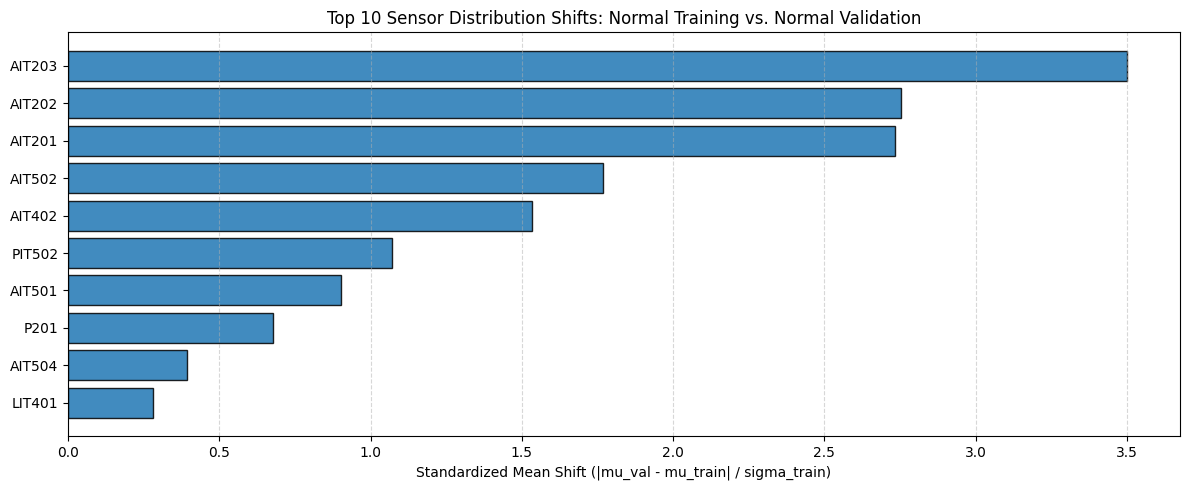

In [23]:
# Formal Distribution Shift Analysis between Training and Validation partitions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load clean normal rows (first 395,298 rows before duplicate segment)
CLEAN_NORMAL_ROWS = 395_298
TRAIN_SPLIT = 221_366
VAL_START = 316_238

df_clean = pd.read_csv(FILES['normal'], nrows=CLEAN_NORMAL_ROWS, low_memory=False)
df_clean.columns = df_clean.columns.str.strip()

DROP_COLS = ['Timestamp', 'Normal/Attack']
EXCLUDED_CONSTANTS = ['P202', 'P204', 'P206', 'P301', 'P401', 'P404', 'P502', 'P601', 'P603']
feature_cols = [c for c in df_clean.columns if c not in DROP_COLS and c not in EXCLUDED_CONSTANTS]

train_df = df_clean.iloc[:TRAIN_SPLIT][feature_cols]
val_df = df_clean.iloc[VAL_START:CLEAN_NORMAL_ROWS][feature_cols]

# Compute distributional metrics per sensor
drift_records = []
for col in feature_cols:
    mu_train = train_df[col].mean()
    std_train = train_df[col].std() + 1e-9
    mu_val = val_df[col].mean()
    std_val = val_df[col].std() + 1e-9
    
    # Standardized mean shift (Cohen's d equivalent) and variance ratio
    norm_mean_shift = abs(mu_val - mu_train) / std_train
    var_ratio = std_val / std_train
    drift_records.append({
        'Sensor': col,
        'Train_Mean': mu_train,
        'Val_Mean': mu_val,
        'Norm_Mean_Shift': norm_mean_shift,
        'Std_Train': std_train,
        'Std_Val': std_val,
        'Var_Ratio': var_ratio,
    })

drift_summary = pd.DataFrame(drift_records).sort_values('Norm_Mean_Shift', ascending=False).reset_index(drop=True)

print("=== TOP 10 OPERATIONAL DRIFT SENSORS (Train vs. Validation) ===")
print(drift_summary[['Sensor', 'Train_Mean', 'Val_Mean', 'Norm_Mean_Shift', 'Var_Ratio']].head(10).to_string(index=False))

# Plot the top 10 sensors with highest distribution shift
plt.figure(figsize=(12, 5))
top10 = drift_summary.head(10)
plt.barh(top10['Sensor'][::-1], top10['Norm_Mean_Shift'][::-1], color='#1f77b4', alpha=0.85, edgecolor='black')
plt.xlabel("Standardized Mean Shift (|mu_val - mu_train| / sigma_train)")
plt.title("Top 10 Sensor Distribution Shifts: Normal Training vs. Normal Validation")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 18.2 Impact on Model Evaluation and False Positive Rates

The executed drift analysis supports **Root Cause #1**: normal-operation data are not stationary across the training and validation partitions.

The top 10 sensors by standardized mean shift were:

| Sensor | Train Mean | Val Mean | Standardized Mean Shift | Std Ratio |
|---|---:|---:|---:|---:|
| AIT203 | 328.367783 | 300.044549 | 3.500539 | 0.764531 |
| AIT202 | 8.447583 | 8.636423 | 2.753007 | 0.547165 |
| AIT201 | 239.008809 | 173.385521 | 2.734229 | 0.116793 |
| AIT502 | 144.254778 | 137.930570 | 1.769597 | 1.076800 |
| AIT402 | 152.638669 | 144.404149 | 1.534836 | 0.731423 |
| PIT502 | 1.240775 | 0.895113 | 1.071548 | 0.269505 |
| AIT501 | 7.822562 | 7.781065 | 0.903413 | 0.611407 |
| P201 | 1.064251 | 1.230066 | 0.676242 | 1.716464 |
| AIT504 | 13.463782 | 15.568970 | 0.392338 | 0.123311 |
| LIT401 | 872.077747 | 901.055788 | 0.281420 | 0.595085 |

This supports the claim that several analytical and process sensors shift between the normal training and normal validation periods. It does **not** by itself establish rule-based false-positive rates or LSTM/TCN reconstruction-error increases. Claims such as a `92.7%` validation flag rate or `45–59%` higher reconstruction error are not produced by this notebook and should not be included here unless sourced from a separate executed analysis.